# Chapitre 12 - Cours 4 : justesse de bout en bout et contraintes

Un service sans état qui se trompe se corrige en redémarrant ; un système qui
**mémorise** (une base de données) garde ses erreurs, parfois pour toujours. Ce notebook
ouvre la section *Aiming for Correctness* : il couvre *The End-to-End Argument for
Databases* (exécution exactement une fois, suppression des doublons, identifiants de
requête, argument de bout en bout) et *Enforcing Constraints* (unicité, journal
partitionné, traitement d'une requête qui touche plusieurs partitions sans validation atomique).

**Plan.**

1. Pourquoi la justesse est difficile.
2. Exécution exactement une fois et suppression des doublons.
3. Identifier chaque requête de bout en bout.
4. L'argument de bout en bout.
5. Faire respecter l'unicité.
6. Une requête sur plusieurs partitions, sans validation atomique.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
SHARD, SHARDS = "partition", "partitions"

## 1. Pourquoi la justesse est difficile (section *Aiming for Correctness*)

On veut des applications **fiables et correctes** : des programmes dont la sémantique est
bien définie et comprise, même en présence de pannes. Depuis une quarantaine d'années,
l'outil de référence est la transaction (atomicité, isolation, durabilité). Ses
fondations sont pourtant plus fragiles qu'il n'y paraît : la confusion autour des
niveaux d'isolation faibles (chapitre 7) en témoigne ; certains domaines
ont abandonné les transactions pour des modèles plus performants mais à la sémantique
floue ; la « cohérence » est souvent invoquée et rarement définie. Les expériences Jepsen
de Kyle Kingsbury ont montré de grands écarts entre les garanties annoncées par certains
produits et leur comportement réel face aux pannes réseau et aux plantages. Et même avec
une base parfaite, l'application doit encore utiliser correctement des réglages
difficiles à comprendre (isolation, quorums).

Une base qui offre des transactions sérialisables ne protège pas d'un **bogue
applicatif** qui écrit des données fausses ou en supprime. C'est un argument en faveur
des données **immuables, en ajout seul** : on se remet bien plus facilement d'une erreur
si le code fautif n'a pas pu **détruire** les bonnes données. Comparons, après un
déploiement bogué qui applique une remise deux fois trop forte pendant une heure, une
table de soldes **mise à jour en place** et un **journal d'événements** dont on dérive les
soldes.

In [2]:
rng = random.Random(4)
events = []                                                 # (heure, client, montant brut, remise)
for h in range(24):
    for _ in range(200):
        events.append((h, rng.randrange(500), round(rng.uniform(5, 200), 2), 0.10))

def montant(evt, bug):
    h, c, brut, remise = evt
    r = remise * 2 if (bug and h == 13) else remise          # le déploiement bogué de 13 h
    return brut * (1 - r)

soldes_en_place = {}
for e in events:                                            # mise à jour en place : seul le résultat survit
    soldes_en_place[e[1]] = soldes_en_place.get(e[1], 0) + montant(e, bug=True)
soldes_corrects = {}
for e in events:                                            # journal : on peut tout rejouer avec le code corrigé
    soldes_corrects[e[1]] = soldes_corrects.get(e[1], 0) + montant(e, bug=False)
faux = sum(abs(soldes_en_place[c] - soldes_corrects[c]) > 1e-9 for c in soldes_corrects)
pd.DataFrame({"approche": ["table mise à jour en place", "journal immuable + rejeu corrigé"],
              "soldes faux après correction du bogue": [faux, 0],
              "comment réparer ?": ["impossible sans l'historique (montants bruts perdus)",
                                    "rejouer les événements avec le code corrigé"]})

,approche,soldes faux après correction du bogue,comment réparer ?
0,table mise à jour en place,160,impossible sans l'historique (montants bruts p...
1,journal immuable + rejeu corrigé,0,rejouer les événements avec le code corrigé


La table en place a « oublié » les montants bruts : les soldes de plusieurs centaines de
clients restent faux, et rien ne permet de savoir de combien. Le journal immuable
conserve l'entrée de chaque décision ; corriger le code et rejouer suffit. L'immuabilité
n'est pas une panacée pour autant : la suite montre une corruption plus subtile, qui
survit à des transactions parfaitement sérialisables.

> **À retenir.** Les garanties d'une base (même sérialisable) ne protègent ni des bogues
> applicatifs ni des mauvais usages. Garder les données immuables, en ajout seul, empêche
> le code fautif de détruire les bonnes données et rend la réparation possible.

## 2. Exécution exactement une fois et suppression des doublons (sections *Exactly-once execution of an operation* et *Duplicate suppression*)

Le problème de l'exécution **exactement une fois** (chapitre 11) : si le
traitement d'un message échoue, on peut abandonner (perte de données) ou réessayer ; mais
si le premier essai avait en fait réussi et que seule la confirmation s'est perdue, le
message est traité **deux fois**. Traiter deux fois est une **corruption** : facturer deux
fois un client, compter deux fois un événement. « Exactement une fois » signifie organiser
le calcul pour que l'effet final soit **le même que sans panne**, même si l'opération a
été réessayée. Le moyen le plus efficace : rendre l'opération **idempotente**, ce qui
demande souvent des métadonnées (l'ensemble des identifiants d'opérations déjà
appliquées) et du fencing lors des basculements (chapitre 8).

TCP supprime déjà les doublons de paquets grâce aux numéros de séquence, mais
**seulement au sein d'une connexion**. Or une transaction est souvent liée à une
connexion : si le client perd la connexion après avoir envoyé `COMMIT` mais avant la
réponse, il ne sait pas si la transaction est validée. S'il se reconnecte et réessaie,
il est hors du périmètre de TCP, et un virement non idempotent est exécuté deux fois.

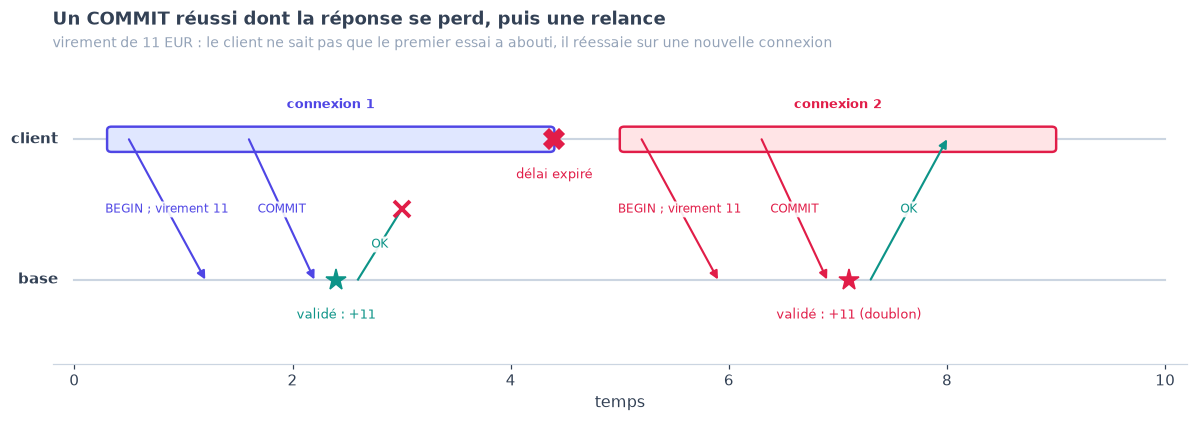

In [3]:
st = SpaceTime(["client", "base"], t_max=10, width=11, lane_height=1.6,
               title="Un COMMIT réussi dont la réponse se perd, puis une relance",
               subtitle="virement de 11 EUR : le client ne sait pas que le premier essai a abouti, il réessaie sur une nouvelle connexion")
st.op("client", 0.3, 4.4, "connexion 1", color=INDIGO)
st.msg("client", 0.5, "base", 1.2, "BEGIN ; virement 11", color=INDIGO)
st.msg("client", 1.6, "base", 2.2, "COMMIT", color=INDIGO)
st.event("base", 2.4, "validé : +11", kind="star", color=TEAL)
st.msg("base", 2.6, "client", 3.4, "OK", color=TEAL, lost=True)
st.event("client", 4.4, "délai expiré", kind="crash")
st.op("client", 5.0, 9.0, "connexion 2", color=ROSE)
st.msg("client", 5.2, "base", 5.9, "BEGIN ; virement 11", color=ROSE)
st.msg("client", 6.3, "base", 6.9, "COMMIT", color=ROSE)
st.event("base", 7.1, "validé : +11 (doublon)", kind="star", color=ROSE)
st.msg("base", 7.3, "client", 8.0, "OK", color=TEAL)
st.show()

La validation atomique (2PC) casse le lien entre connexion et transaction (le
coordinateur se reconnecte et dit à la base de valider ou d'annuler une transaction en
doute), mais ne règle pas tout : il reste le réseau entre **l'appareil de l'utilisateur**
et le serveur d'application. Un utilisateur sur une connexion mobile faible envoie un
formulaire (`POST`), perd le signal avant la réponse, voit un message d'erreur et
réessaie (« Voulez-vous vraiment renvoyer le formulaire ? » : oui, il veut que
l'opération ait lieu). Pour le serveur web c'est une nouvelle requête, pour la base une
nouvelle transaction. Simulons un client qui fait 2 000 virements de 11 EUR, et dont la
réponse se perd avec une probabilité $p$ ; à chaque perte, il réessaie (jusqu'à 5 envois).

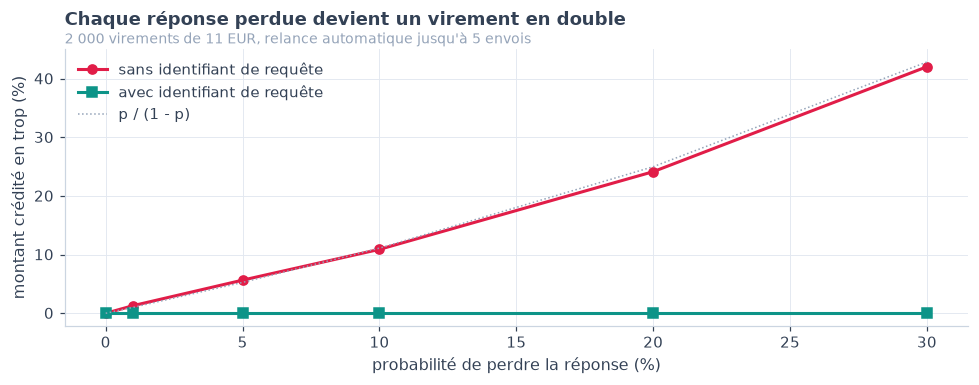

,p (réponse perdue),voulu (EUR),crédité sans identifiant,crédité avec identifiant,envois
0,0.00,22000.0,22000.0,22000.0,2000
1,0.01,22000.0,22286.0,22000.0,2026
2,0.05,22000.0,23243.0,22000.0,2113
3,0.10,22000.0,24398.0,22000.0,2218
4,0.20,22000.0,27313.0,22000.0,2483
5,0.30,22000.0,31251.0,22000.0,2841


In [4]:
ps = [0.0, 0.01, 0.05, 0.1, 0.2, 0.3]
rows = []
for p in ps:
    naive = dfl.retrying_client(dfl.make_bank_db({1: 0.0, 2: 1e6}), 2000, p, use_ids=False, seed=1)
    dedup = dfl.retrying_client(dfl.make_bank_db({1: 0.0, 2: 1e6}), 2000, p, use_ids=True, seed=1)
    rows.append({"p (réponse perdue)": p, "voulu (EUR)": naive["intended"], "crédité sans identifiant": naive["credited"],
                 "crédité avec identifiant": dedup["credited"], "envois": naive["attempts"]})
R = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(R.iloc[:, 0] * 100, (R.iloc[:, 2] / R.iloc[:, 1] - 1) * 100, "o-", color=ROSE, label="sans identifiant de requête")
ax.plot(R.iloc[:, 0] * 100, (R.iloc[:, 3] / R.iloc[:, 1] - 1) * 100, "s-", color=TEAL, label="avec identifiant de requête")
ax.plot(R.iloc[:, 0] * 100, [p / (1 - p) * 100 for p in R.iloc[:, 0]], color=GRAY, ls=":", lw=1, label="p / (1 - p)")
ax.set_xlabel("probabilité de perdre la réponse (%)"); ax.set_ylabel("montant crédité en trop (%)")
ax.set_title("Chaque réponse perdue devient un virement en double")
subtitle(ax, "2 000 virements de 11 EUR, relance automatique jusqu'à 5 envois")
ax.legend(); plt.tight_layout(); plt.show()
R

Sans identifiant, le surplus crédité suit à peu près $p/(1-p)$ (le nombre moyen d'envois
supplémentaires d'une loi géométrique, tronquée à 5 envois) : 11 % de trop quand une
réponse sur dix se perd. Avec un identifiant, le montant est exact quel que soit $p$.
L'exemple classique du virement en deux `UPDATE`, qu'on cite pour illustrer l'atomicité,
n'est donc **pas correct** dans la vraie vie, et les vraies banques ne fonctionnent pas
ainsi.

> **À retenir.** La suppression des doublons de TCP s'arrête à la connexion, celle des
> transactions à la base, celle du 2PC au coordinateur. Une relance de l'utilisateur
> traverse toutes ces couches : sans mesure de bout en bout, chaque réponse perdue
> devient une exécution en double.